# Evaluación de modelos v2 — UrbanSafe AI (Week 09)

Re-evaluación de los modelos de week08 con un protocolo más exigente, más modelos (incluido
**Chronos-2**) y evaluación de **todos** los componentes del producto: pronóstico de demanda,
aforo multiclase, ETA, regla de recomendación (AC-03) y anomalías.

| | week08 | **week09 (v2)** |
|--|--|--|
| Días de evaluación | 5 martes (2 atípicos sin marcar: paro 04-nov y feriado 09-dic) | **61 días** (1 nov – 31 dic), todos los días de la semana, estratificados |
| Selección del ganador | sobre los mismos días de test | **en validación** (15–31 oct); el test solo reporta |
| Calendario | 11 feriados | **16 feriados oficiales** + 8 paros de transportistas verificados |
| Modelos | Chronos-Bolt, LightGBM (recursivo), AutoETS, 2 baselines | + **Chronos-2** (covariable feriado), **MSTL** (24 h + 168 h), **LightGBM directo** (Tweedie), `media_4sem`, ensemble |
| Bandas | Chronos nativas; ±15 % fijo para el resto | **conformal** por hora (cobertura objetivo 80 %) |
| Aforo | clasificador aparte (no usado por el producto) | **cascada real del producto** (pronóstico → crowding → clase), F1-weighted y macro |
| ETA / regla U / anomalías | sin evaluar | ETA proxy, **AC-03** con baseline "siempre abordar", anomalías vs calendario de eventos |

Cómputo pesado: `evaluar_v2.py` (≈1 h en CPU). Este notebook **solo lee** `results_v2/` (versionado),
así que se ejecuta en segundos. Módulo: `model_atu_v2.py` (extiende `model_atu_common.py` de week08).

## 0. Setup — ¿qué vamos a hacer?
Cargar rutas, la paleta de colores (fija por modelo) y los resultados de los 4 sistemas.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

def find_raiz():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "code" / "model" / "model_atu_v2.py").exists():
            return cand
    raise FileNotFoundError("no encuentro code/model/model_atu_v2.py")

RAIZ = find_raiz()
sys.path.insert(0, str(RAIZ / "code" / "model"))
import model_atu_v2 as V

RES = RAIZ / "code" / "model" / "results_v2"
FIGS = RAIZ / "docs" / "images" / "model_v2"
FIGS.mkdir(parents=True, exist_ok=True)
SISTEMAS = ["metro_l1", "troncal", "corredor", "alimentador"]
TITULO = {"metro_l1": "Metro Línea 1", "troncal": "Metropolitano troncal",
          "corredor": "Corredores complementarios", "alimentador": "Alimentadores"}

# Paleta de referencia (skill dataviz): candidatos en orden categórico fijo, baselines en grises
COLOR = {"chronos2": "#2a78d6", "lightgbm": "#eb6834", "mstl": "#1baf7a", "autoets": "#eda100",
         "chronos_bolt": "#e87ba4", "ensemble": "#008300",
         "media_4sem": "#52514e", "naive_7d": "#898781", "hora_media": "#c3c2b7"}
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "semibold",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.facecolor": "#fcfcfb",
    "figure.facecolor": "white", "lines.linewidth": 2, "lines.solid_capstyle": "round",
})

def guardar(fig, nombre):
    fig.savefig(FIGS / nombre, bbox_inches="tight")
    plt.show()
    print("[figura]", (FIGS / nombre).relative_to(RAIZ))

def leer(sistema, archivo, **kw):
    return pd.read_csv(RES / sistema / archivo, **kw)

resumen = {s: json.loads((RES / s / "resumen.json").read_text(encoding="utf-8")) for s in SISTEMAS}
pd.DataFrame([{"sistema": s, "series": r["n_series"], "ganador (validación)": r["ganador_validacion"],
               "top-3 validación": ", ".join(r["top3_validacion"]),
               "árboles LightGBM": r["lgb_n_estimators"]} for s, r in resumen.items()])

,sistema,series,ganador (validación),top-3 validación,árboles LightGBM
0,metro_l1,26,ensemble,"lightgbm, chronos2, mstl",459
1,troncal,45,ensemble,"lightgbm, chronos2, mstl",135
2,corredor,12,ensemble,"lightgbm, chronos2, chronos_bolt",126
3,alimentador,23,lightgbm,"lightgbm, chronos_bolt, chronos2",586


## 1. ¿Con qué días se evaluaba antes? — motivación
El walk-forward de week08 usaba 5 martes. Con el calendario completo, **2 de los 5 eran atípicos**:
el 04-nov-2025 hubo **paro de transportistas** y el 09-dic-2025 fue **feriado** (Batalla de Ayacucho),
que no estaba en la lista de 11 feriados de week08.

In [2]:
dias_w08 = ["2025-11-04", "2025-11-11", "2025-11-18", "2025-12-02", "2025-12-09"]
display(pd.DataFrame({"día eval week08": dias_w08,
                      "día": [pd.Timestamp(d).day_name() for d in dias_w08],
                      "tipo": [V.tipo_evento(d) for d in dias_w08]}))
cal = V.calendario_eventos(2025)
print(cal["tipo"].value_counts().to_string())
cal

,día eval week08,día,tipo
0,2025-11-04,Tuesday,paro
1,2025-11-11,Tuesday,normal
2,2025-11-18,Tuesday,normal
3,2025-12-02,Tuesday,normal
4,2025-12-09,Tuesday,feriado


tipo
feriado    16
paro        8
vispera     2


,fecha,tipo,descripcion,fuente
0,2025-01-01,feriado,Año Nuevo,MTPE (calendario oficial)
1,2025-02-06,paro,Paro de transportistas Lima y Callao,https://larepublica.pe/sociedad/2025/02/05/par...
2,2025-04-07,paro,Paro de transportistas Lima Norte (Metropolita...,https://www.infobae.com/peru/2025/04/07/metrop...
3,2025-04-10,paro,Paro de transportistas de 24 h,https://www.infobae.com/peru/2025/04/10/paro-d...
4,2025-04-17,feriado,Jueves Santo,MTPE (calendario oficial)
5,2025-04-18,feriado,Viernes Santo,MTPE (calendario oficial)
6,2025-05-01,feriado,Día del Trabajo,MTPE (calendario oficial)
7,2025-06-07,feriado,Batalla de Arica y Día de la Bandera,MTPE (calendario oficial)
8,2025-06-29,feriado,San Pedro y San Pablo,MTPE (calendario oficial)
9,2025-07-23,feriado,Día de la Fuerza Aérea del Perú,MTPE (calendario oficial)


## 2. Protocolo v2 — ¿qué vamos a hacer?
* **Variable objetivo:** validaciones (abordajes registrados) por unidad (estación o ruta) y hora;
  horizonte 24 h; contexto hasta el día previo 23:00 (*rolling-origin* diario, sin fuga de información).
* **Validación** 15–31 oct 2025 (17 días): se elige el ganador por WMAPE y el top-3 para el ensemble.
* **Test** 1 nov – 31 dic 2025 (61 días): solo se reporta. Estratos: normales, atípicos (feriado, paro,
  víspera), laborables, fin de semana.
* **Métricas:** WMAPE (criterio, comparable entre sistemas), MAE, RMSE, MASE (vs naive estacional 168 h),
  WQL (modelos probabilísticos), cobertura del intervalo 80 %; Diebold-Mariano (HLN) para significancia.
* **Modelos:** baselines (`naive_7d`, `hora_media`, `media_4sem`), AutoETS (24 h, ventana 8 sem.),
  MSTL (24 h + 168 h, 8 sem.), LightGBM directo (Tweedie, lags ≥ 24 h, re-entreno semanal),
  Chronos-Bolt (week08) y Chronos-2 (zero-shot, contexto 2048 h, feriado como covariable futura).

## 3. Pronóstico de demanda — resultados
### 3.1 Selección en validación (15–31 oct)

In [3]:
val = pd.concat([leer(s, "seleccion_validacion.csv") for s in SISTEMAS])
val.pivot_table(index="modelo", columns="sistema", values="WMAPE")[SISTEMAS].round(3).sort_values("metro_l1")

sistema,metro_l1,troncal,corredor,alimentador
modelo,,,,
ensemble,0.072,0.103,0.095,0.427
lightgbm,0.075,0.106,0.097,0.422
chronos2,0.077,0.110,0.101,0.452
mstl,0.082,0.120,0.113,0.499
media_4sem,0.085,0.123,0.118,0.422
chronos_bolt,0.087,0.130,0.104,0.436
naive_7d,0.097,0.130,0.122,0.537
hora_media,0.190,0.292,0.273,0.528
autoets,0.200,0.338,0.291,0.575


### 3.2 Test (61 días): WMAPE por modelo — el ganador de validación resaltado

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


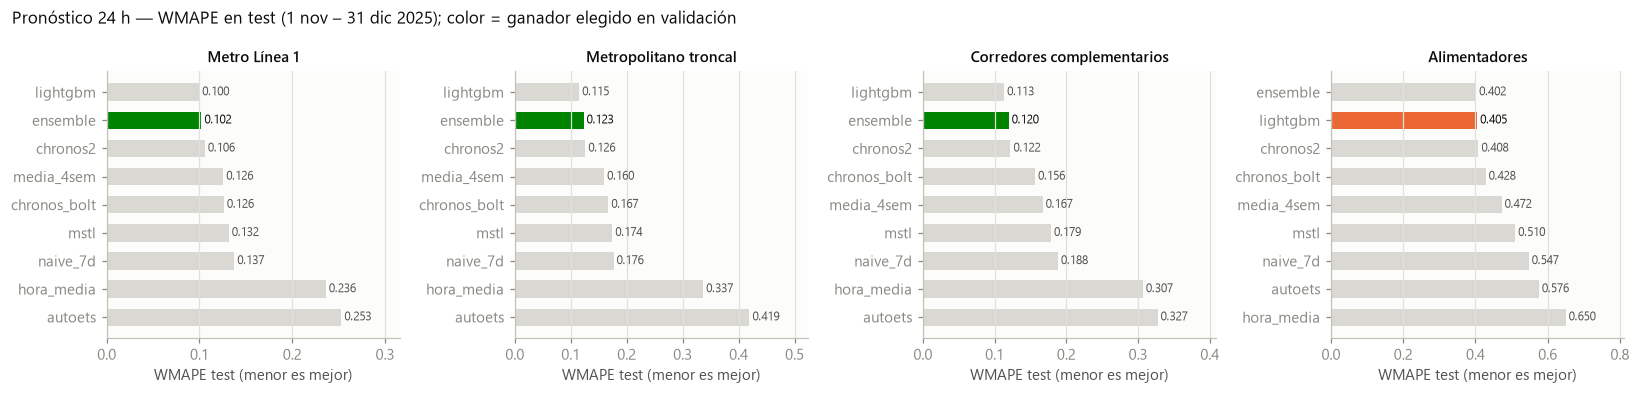

[figura] docs\images\model_v2\wmape_test_por_sistema.png


In [4]:
tab = pd.concat([leer(s, "metricas_test.csv") for s in SISTEMAS])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=False)
for ax, s in zip(axes, SISTEMAS):
    t = tab[(tab.sistema == s) & (tab.estrato == "todos")].sort_values("WMAPE", ascending=False)
    gan = resumen[s]["ganador_validacion"]
    cols = [COLOR.get(m, MUTED) if m == gan else "#d9d8d2" for m in t.modelo]
    ax.barh(t.modelo, t.WMAPE, color=cols, height=0.62)
    for y, (m, w) in enumerate(zip(t.modelo, t.WMAPE)):
        ax.text(w, y, f" {w:.3f}", va="center", fontsize=8, color=INK if m == gan else INK2)
    ax.set_title(TITULO[s], fontsize=10); ax.set_xlabel("WMAPE test (menor es mejor)")
    ax.grid(axis="y", visible=False); ax.set_xlim(0, t.WMAPE.max() * 1.25)
fig.suptitle("Pronóstico 24 h — WMAPE en test (1 nov – 31 dic 2025); color = ganador elegido en validación",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
guardar(fig, "wmape_test_por_sistema.png")

In [5]:
piv = tab.pivot_table(index=["sistema", "modelo"], columns="estrato", values="WMAPE")
piv = piv[[c for c in ["todos", "normales", "atipicos", "laborables", "fin_de_semana", "feriado", "paro"] if c in piv]]
piv.round(3)

estrato                   todos  normales  atipicos  laborables  fin_de_semana  feriado   paro
sistema     modelo                                                                            
alimentador autoets       0.576     0.560     0.759       0.492          0.827    0.888  0.491
            chronos2      0.408     0.386     0.673       0.372          0.443    0.750  0.402
            chronos_bolt  0.428     0.395     0.828       0.378          0.460    1.046  0.415
            ensemble      0.402     0.381     0.647       0.369          0.431    0.692  0.394
            hora_media    0.650     0.608     1.157       0.468          1.156    1.506  0.424
            lightgbm      0.405     0.393     0.548       0.382          0.435    0.480  0.390
            media_4sem    0.472     0.425     1.044       0.414          0.465    1.360  0.405
            mstl          0.510     0.477     0.900       0.446          0.602    1.085  0.481
            naive_7d      0.547     0.508     1.018       0.494          0.564    1.368  0.495
corredor    autoets       0.327     0.306     0.589       0.235          0.582    0.899  0.225
            chronos2      0.122     0.094     0.472       0.090          0.112    0.583  0.270
            chronos_bolt  0.156     0.114     0.690       0.102          0.161    1.098  0.266
            ensemble      0.120     0.092     0.465       0.088          0.108    0.566  0.271
            hora_media    0.307     0.278     0.672       0.199          0.581    1.141  0.173
            lightgbm      0.113     0.096     0.336       0.094          0.103    0.251  0.281
            media_4sem    0.167     0.111     0.870       0.109          0.121    1.451  0.231
            mstl          0.179     0.134     0.746       0.119          0.191    1.169  0.241
            naive_7d      0.188     0.140     0.794       0.138          0.150    1.403  0.290
metro_l1    autoets       0.253     0.234     0.437       0.165          0.418    0.610  0.159
            chronos2      0.106     0.079     0.363       0.074          0.092    0.455  0.164
            chronos_bolt  0.126     0.093     0.442       0.082          0.123    0.637  0.164
            ensemble      0.102     0.076     0.354       0.071          0.090    0.445  0.157
            hora_media    0.236     0.220     0.394       0.162          0.377    0.559  0.166
            lightgbm      0.100     0.077     0.313       0.071          0.095    0.368  0.154
            media_4sem    0.126     0.091     0.460       0.084          0.108    0.673  0.140
            mstl          0.132     0.097     0.462       0.089          0.118    0.660  0.156
            naive_7d      0.137     0.106     0.438       0.105          0.109    0.679  0.192
troncal     autoets       0.419     0.397     0.693       0.297          0.787    1.049  0.235
            chronos2      0.126     0.085     0.630       0.078          0.111    0.809  0.254
            chronos_bolt  0.167     0.116     0.796       0.097          0.190    1.223  0.255
            ensemble      0.123     0.084     0.604       0.077          0.110    0.752  0.259
            hora_media    0.337     0.311     0.652       0.212          0.695    1.075  0.170
            lightgbm      0.115     0.087     0.452       0.081          0.113    0.367  0.303
            media_4sem    0.160     0.102     0.863       0.094          0.133    1.367  0.238
            mstl          0.174     0.120     0.839       0.106          0.175    1.319  0.240
            naive_7d      0.176     0.122     0.841       0.116          0.148    1.383  0.460

### 3.3 ¿Cuánto mejora el ganador frente a la mejor baseline? (WMAPE y MASE, test)

In [6]:
filas = []
for s in SISTEMAS:
    t = tab[(tab.sistema == s)]
    gan = resumen[s]["ganador_validacion"]
    for est in ["todos", "normales", "atipicos"]:
        te = t[t.estrato == est]
        b = te[te.modelo.isin(V.BASELINES)].sort_values("WMAPE").iloc[0]
        g = te[te.modelo == gan].iloc[0]
        filas.append({"sistema": s, "estrato": est, "ganador": gan, "WMAPE ganador": g.WMAPE,
                      "mejor baseline": b.modelo, "WMAPE baseline": b.WMAPE,
                      "mejora relativa": 1 - g.WMAPE / b.WMAPE, "MASE ganador": g.MASE})
mejora = pd.DataFrame(filas)
mejora.round(3)

,sistema,estrato,ganador,WMAPE ganador,mejor baseline,WMAPE baseline,mejora relativa,MASE ganador
0,metro_l1,todos,ensemble,0.102,media_4sem,0.126,0.187,0.952
1,metro_l1,normales,ensemble,0.076,media_4sem,0.091,0.164,0.730
2,metro_l1,atipicos,ensemble,0.354,hora_media,0.394,0.101,2.665
3,troncal,todos,ensemble,0.123,media_4sem,0.160,0.230,0.947
4,troncal,normales,ensemble,0.084,media_4sem,0.102,0.182,0.713
5,troncal,atipicos,ensemble,0.604,hora_media,0.652,0.072,2.755
6,corredor,todos,ensemble,0.120,media_4sem,0.167,0.284,0.807
7,corredor,normales,ensemble,0.092,media_4sem,0.111,0.171,0.674
8,corredor,atipicos,ensemble,0.465,hora_media,0.672,0.308,1.836
9,alimentador,todos,lightgbm,0.405,media_4sem,0.472,0.144,0.712


### 3.4 Error diario en test: ganador vs mejor baseline (días atípicos marcados)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


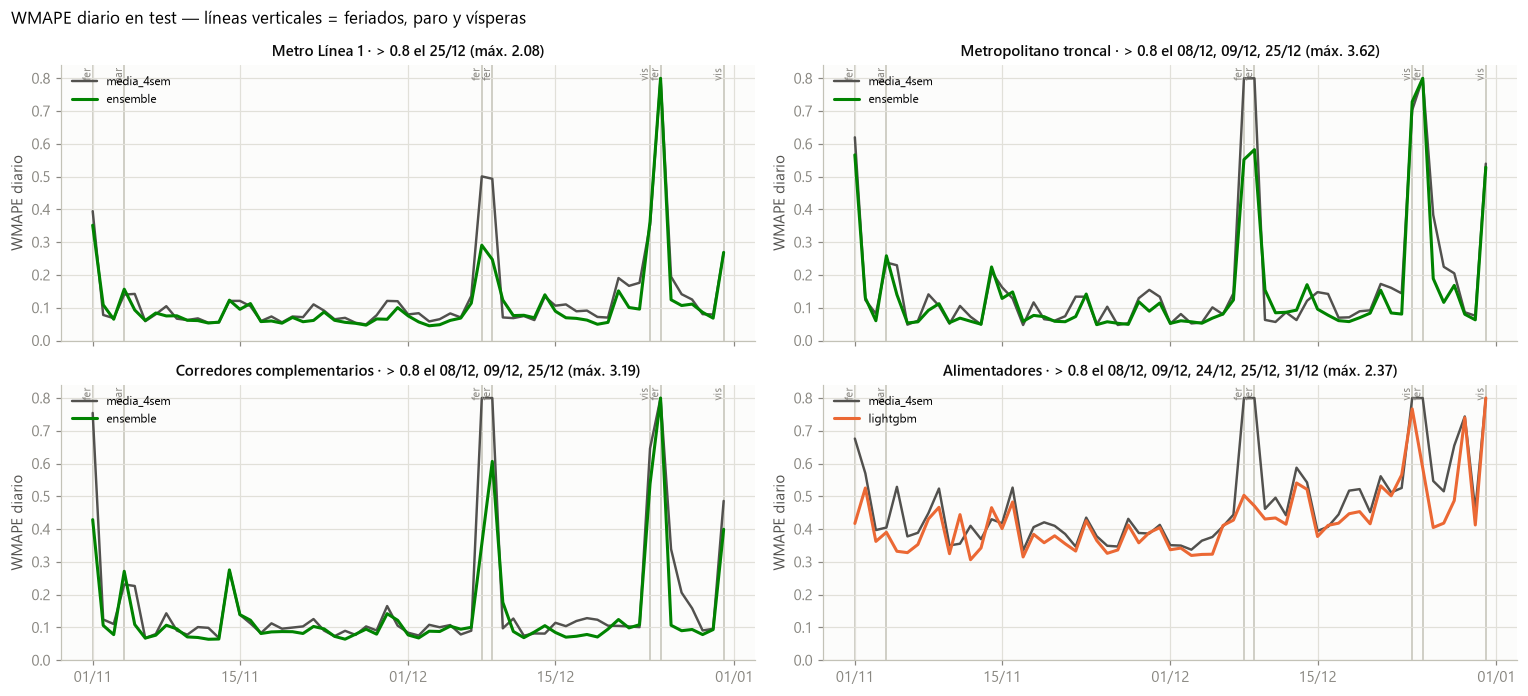

[figura] docs\images\model_v2\wmape_diario_test.png


In [7]:
dia = pd.concat([leer(s, "metricas_diarias_test.csv") for s in SISTEMAS])
dia["dia"] = pd.to_datetime(dia["dia"])
fig, axes = plt.subplots(2, 2, figsize=(14, 6.4), sharex=True)
for ax, s in zip(axes.ravel(), SISTEMAS):
    gan = resumen[s]["ganador_validacion"]
    base = mejora[(mejora.sistema == s) & (mejora.estrato == "todos")]["mejor baseline"].iloc[0]
    TOPE = 0.8   # eje recortado: Navidad llega a WMAPE > 1 y aplastaría el resto
    serie = {}
    for m in (base, gan):
        d = dia[(dia.sistema == s) & (dia.modelo == m)].sort_values("dia")
        serie[m] = d.set_index("dia").WMAPE
        ax.plot(d.dia, d.WMAPE.clip(upper=TOPE), color=COLOR.get(m, MUTED), lw=2 if m == gan else 1.6, label=m)
    fuera = sorted(set(serie[base][serie[base] > TOPE].index) | set(serie[gan][serie[gan] > TOPE].index))
    nota = ""
    if fuera:
        mx = max(serie[base].max(), serie[gan].max())
        nota = f" · > 0.8 el {', '.join(f'{d:%d/%m}' for d in fuera)} (máx. {mx:.2f})"
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.set_ylim(0, TOPE * 1.05)
    at = dia[(dia.sistema == s) & (dia.modelo == gan) & (dia.tipo_dia != "normal")]
    for _, r in at.iterrows():
        ax.axvline(r.dia, color=AXIS, lw=1, zorder=0)
        ax.text(r.dia, TOPE * 1.04, r.tipo_dia[:3], rotation=90, fontsize=7, color=MUTED, ha="right", va="top")
    ax.set_title(TITULO[s] + nota, fontsize=9.5); ax.set_ylabel("WMAPE diario")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("WMAPE diario en test — líneas verticales = feriados, paro y vísperas", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "wmape_diario_test.png")

### 3.5 ¿La diferencia es significativa? — Diebold-Mariano (MAE diario, test)

In [8]:
dm = pd.concat([leer(s, "diebold_mariano.csv") for s in SISTEMAS])
dm["significativo_5%"] = dm["p_valor"] < 0.05
dm.round(4)

,sistema,ganador,vs,dm_stat,p_valor,significativo_5%
0,metro_l1,ensemble,naive_7d,-3.3252,0.0015,True
1,metro_l1,ensemble,hora_media,-11.9052,0.0000,True
2,metro_l1,ensemble,media_4sem,-3.8028,0.0003,True
3,metro_l1,ensemble,autoets,-11.0320,0.0000,True
4,metro_l1,ensemble,mstl,-5.4078,0.0000,True
5,metro_l1,ensemble,lightgbm,0.6839,0.4967,False
6,metro_l1,ensemble,chronos_bolt,-4.2997,0.0001,True
7,metro_l1,ensemble,chronos2,-1.8404,0.0707,False
0,troncal,ensemble,naive_7d,-2.7864,0.0071,True
1,troncal,ensemble,hora_media,-10.5656,0.0000,True


## 4. Intervalos de predicción (objetivo 80 %)

In [9]:
inter = pd.concat([leer(s, "intervalos_test.csv") for s in SISTEMAS])
inter.pivot_table(index=["modelo", "intervalo"], columns="sistema", values="cobertura")[SISTEMAS].round(3)

sistema                   metro_l1  troncal  corredor  alimentador
modelo       intervalo                                            
autoets      conformal       0.785    0.798     0.830        0.820
             proxy_15pct     0.462    0.275     0.350        0.201
chronos2     conformal       0.782    0.790     0.805        0.810
             nativo          0.695    0.697     0.740        0.757
chronos_bolt conformal       0.783    0.821     0.829        0.839
             nativo          0.865    0.862     0.839        0.794
ensemble     conformal       0.771    0.779     0.804        0.814
             proxy_15pct     0.796    0.517     0.508        0.167
lightgbm     conformal       0.769    0.778     0.806        0.811
             proxy_15pct     0.784    0.518     0.512        0.169
mstl         conformal       0.765    0.770     0.793        0.816
             proxy_15pct     0.720    0.487     0.470        0.243

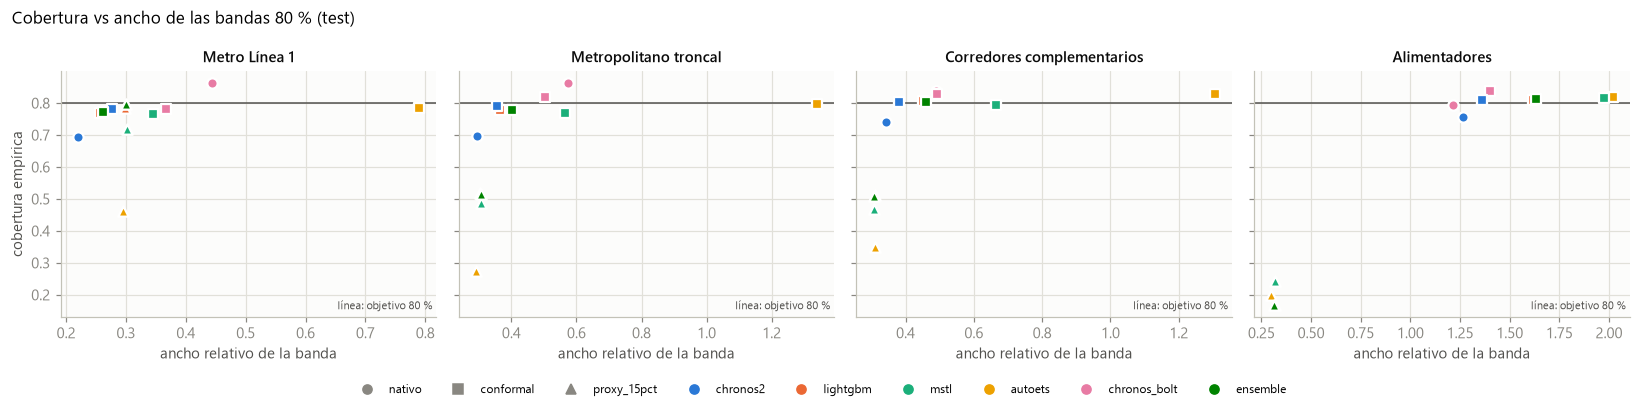

[figura] docs\images\model_v2\cobertura_intervalos.png


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
marc = {"nativo": "o", "conformal": "s", "proxy_15pct": "^"}
for ax, s in zip(axes, SISTEMAS):
    t = inter[inter.sistema == s]
    for _, r in t.iterrows():
        ax.scatter(r.ancho_rel, r.cobertura, s=46, marker=marc[r.intervalo], color=COLOR.get(r.modelo, MUTED),
                   edgecolor="white", linewidth=1.5, zorder=3)
    ax.axhline(0.8, color=INK2, lw=1)
    ax.text(0.99, 0.02, "línea: objetivo 80 %", transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color=INK2)
    ax.set_title(TITULO[s], fontsize=10); ax.set_xlabel("ancho relativo de la banda")
axes[0].set_ylabel("cobertura empírica")
from matplotlib.lines import Line2D
h1 = [Line2D([], [], marker=m, ls="", color=MUTED, label=k) for k, m in marc.items()]
h2 = [Line2D([], [], marker="o", ls="", color=COLOR[m], label=m) for m in ["chronos2", "lightgbm", "mstl", "autoets", "chronos_bolt", "ensemble"]]
fig.legend(handles=h1 + h2, ncol=9, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.08), fontsize=8)
fig.suptitle("Cobertura vs ancho de las bandas 80 % (test)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "cobertura_intervalos.png")

## 5. Aforo multiclase — la cascada real del producto
Clase verdadera = `crowding_index` calculado con las validaciones **reales** (definición de week08,
verificada 100 % idéntica a `attach_ops`). Clase predicha = mismo cálculo con el **pronóstico**.
Baselines: clase mayoritaria, moda histórica (unidad × hora × tipo de día) y cascada con `naive_7d`.
También se reporta el clasificador directo HistGB de week08.

In [11]:
af = pd.concat([leer(s, "aforo_test.csv") for s in SISTEMAS])
sel = ["mayoritaria", "moda_historica", "cascada_naive_7d", "histgb_directo"]
af["es_ganador"] = [m == f"cascada_{resumen[s]['ganador_validacion']}" for s, m in zip(af.sistema, af.modelo)]
vista = af[af.modelo.isin(sel) | af.es_ganador].copy()
vista["RNF-01"] = (vista.accuracy >= 0.75) & (vista.f1_macro >= 0.72)
vista["AC-02"] = vista[["f1_Asientos", "f1_De_pie", "f1_Saturado"]].min(axis=1) >= 0.72
cols = ["sistema", "modelo", "accuracy", "balanced_acc", "f1_weighted", "f1_macro",
        "f1_Asientos", "f1_De_pie", "f1_Saturado", "RNF-01", "AC-02"]
vista[cols].round(3)

,sistema,modelo,accuracy,balanced_acc,f1_weighted,f1_macro,f1_Asientos,f1_De_pie,f1_Saturado,RNF-01,AC-02
0,metro_l1,cascada_naive_7d,0.892,0.880,0.892,0.872,0.935,0.838,0.843,True,True
7,metro_l1,cascada_ensemble,0.919,0.905,0.919,0.904,0.952,0.878,0.883,True,True
8,metro_l1,mayoritaria,0.551,0.333,0.391,0.237,0.710,0.000,0.000,False,False
9,metro_l1,moda_historica,0.881,0.831,0.879,0.853,0.932,0.812,0.815,True,True
10,metro_l1,histgb_directo,0.881,0.835,0.879,0.856,0.930,0.813,0.826,True,True
0,troncal,cascada_naive_7d,0.906,0.898,0.906,0.887,0.941,0.856,0.863,True,True
7,troncal,cascada_ensemble,0.905,0.911,0.907,0.899,0.932,0.858,0.905,True,True
8,troncal,mayoritaria,0.582,0.333,0.428,0.245,0.735,0.000,0.000,False,False
9,troncal,moda_historica,0.920,0.889,0.920,0.904,0.952,0.869,0.892,True,True
10,troncal,histgb_directo,0.921,0.887,0.920,0.903,0.953,0.871,0.884,True,True


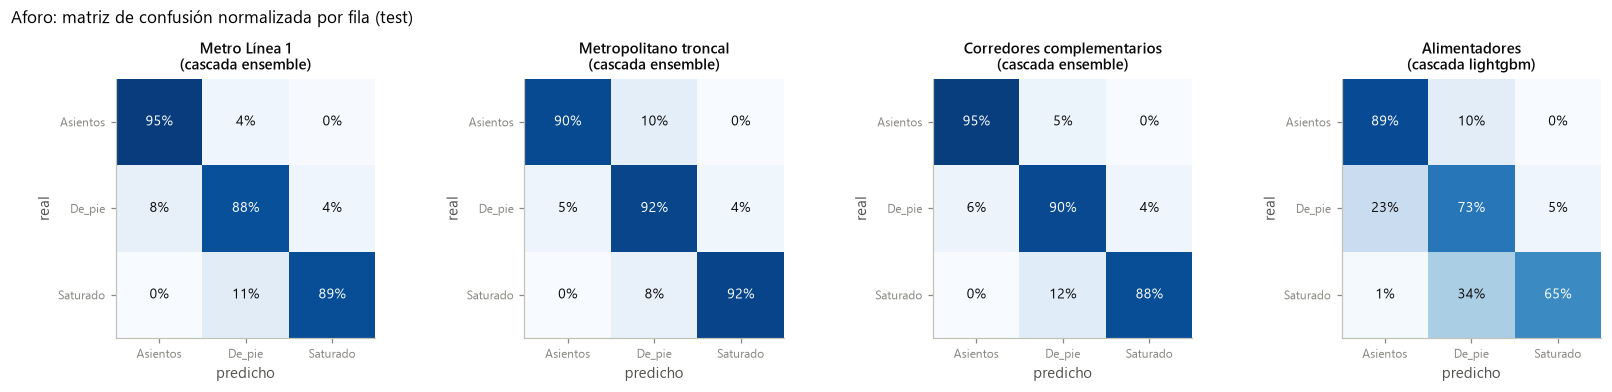

[figura] docs\images\model_v2\aforo_confusion_ganador.png


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
clases = ["Asientos", "De_pie", "Saturado"]
for ax, s in zip(axes, SISTEMAS):
    gan = resumen[s]["ganador_validacion"]
    cm = pd.read_csv(RES / s / f"confusion_cascada_{gan}.csv", index_col=0).reindex(index=clases, columns=clases).fillna(0)
    norm = cm.div(cm.sum(axis=1), axis=0)
    ax.imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{norm.values[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if norm.values[i, j] > 0.55 else INK)
    ax.set_xticks(range(3), clases, fontsize=8); ax.set_yticks(range(3), clases, fontsize=8)
    ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.grid(False)
    ax.set_title(f"{TITULO[s]}\n(cascada {gan})", fontsize=9.5)
fig.suptitle("Aforo: matriz de confusión normalizada por fila (test)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "aforo_confusion_ganador.png")

### 5.1 Sensibilidad: umbrales por franja (week08) vs umbrales globales

In [13]:
sens = pd.concat([leer(s, "aforo_sensibilidad_umbrales.csv") for s in SISTEMAS])
sens[["sistema", "umbrales", "modelo", "accuracy", "f1_weighted", "f1_macro", "pct_saturado_noche"]].round(3)

,sistema,umbrales,modelo,accuracy,f1_weighted,f1_macro,pct_saturado_noche
0,metro_l1,por_franja,cascada_naive_7d,0.892,0.892,0.872,0.132
1,metro_l1,por_franja,cascada_ensemble,0.919,0.919,0.904,0.132
2,metro_l1,por_franja,mayoritaria,0.551,0.391,0.237,0.132
3,metro_l1,global,cascada_ensemble,0.932,0.933,0.915,0.038
4,metro_l1,global,cascada_naive_7d,0.907,0.907,0.885,0.038
5,metro_l1,global,mayoritaria,0.554,0.396,0.238,0.038
0,troncal,por_franja,cascada_naive_7d,0.906,0.906,0.887,0.108
1,troncal,por_franja,cascada_ensemble,0.905,0.907,0.899,0.108
2,troncal,por_franja,mayoritaria,0.582,0.428,0.245,0.108
3,troncal,global,cascada_ensemble,0.938,0.939,0.925,0.014


## 6. ETA (proxy) y regla de recomendación (AC-03)
* **ETA:** sin GPS/AVL no hay llegadas reales. Se mide el **error del ETA inducido por el modelo**:
  `ETA(clase predicha)` vs `ETA(clase observada)`, en minutos.
* **AC-03:** "recomendación correcta ≥ 80 %". Se compara la regla U aplicada a las clases predichas
  contra la misma regla aplicada a las clases reales; baseline **"siempre abordar"**.

In [14]:
ru = pd.concat([leer(s, "regla_u_test.csv") for s in SISTEMAS])
ru["es_ganador"] = [m == f"cascada_{resumen[s]['ganador_validacion']}" for s, m in zip(ru.sistema, ru.modelo)]
vru = ru[ru.es_ganador | ru.modelo.isin(["siempre_abordar", "cascada_naive_7d", "histgb_directo"])].copy()
vru["AC-03 (≥80 %)"] = vru.acuerdo >= 0.80
eta = af[af.es_ganador | af.modelo.isin(["cascada_naive_7d", "mayoritaria"])][["sistema", "modelo", "eta_mae_min"]]
display(vru[["sistema", "modelo", "acuerdo", "balanced_acc", "f1_macro", "pct_no_abordar_real", "AC-03 (≥80 %)"]].round(3))
eta.round(3)

,sistema,modelo,acuerdo,balanced_acc,f1_macro,pct_no_abordar_real,AC-03 (≥80 %)
0,metro_l1,cascada_naive_7d,0.960,0.842,0.807,0.069,True
7,metro_l1,cascada_ensemble,0.969,0.846,0.843,0.069,True
10,metro_l1,histgb_directo,0.962,0.730,0.776,0.069,True
11,metro_l1,siempre_abordar,0.931,0.333,0.321,0.069,True
0,troncal,cascada_naive_7d,0.969,0.885,0.813,0.053,True
7,troncal,cascada_ensemble,0.978,0.904,0.863,0.053,True
10,troncal,histgb_directo,0.976,0.791,0.833,0.053,True
11,troncal,siempre_abordar,0.947,0.333,0.324,0.053,True
0,corredor,cascada_naive_7d,0.958,0.911,0.892,0.103,True
7,corredor,cascada_ensemble,0.976,0.935,0.935,0.103,True


,sistema,modelo,eta_mae_min
0,metro_l1,cascada_naive_7d,0.101
7,metro_l1,cascada_ensemble,0.075
8,metro_l1,mayoritaria,0.421
0,troncal,cascada_naive_7d,0.077
7,troncal,cascada_ensemble,0.068
8,troncal,mayoritaria,0.312
0,corredor,cascada_naive_7d,0.173
7,corredor,cascada_ensemble,0.104
8,corredor,mayoritaria,0.623
0,alimentador,cascada_naive_7d,0.201


## 7. Anomalías — ¿se detectan los días atípicos reales?
Etiquetas: feriados + paros de 2025 (calendario con fuentes). Detectores evaluados sobre feb–dic 2025:
* **residuo vs `media_4sem` + z robusto** (propuesto; causal, mediana/MAD de 8 semanas),
* z del total diario vs el mismo día de la semana (baseline ingenuo),
* **IsolationForest de week08** (features por celda, % de celdas anómalas por día).

In [15]:
an = pd.concat([leer(s, "anomalias_eval.csv") for s in SISTEMAS])
an[["sistema", "detector", "n_dias", "n_pos", "pr_auc", "roc_auc", "precision_at_k", "precision", "recall", "f1"]].round(3)

,sistema,detector,n_dias,n_pos,pr_auc,roc_auc,precision_at_k,precision,recall,f1
0,metro_l1,residuo_media4sem_zrobusto,320,22,0.595,0.921,0.591,0.320,0.727,0.444
1,metro_l1,z_total_mismo_dow,334,23,0.590,0.922,0.565,0.588,0.435,0.500
2,metro_l1,isolation_forest_w08,334,23,0.408,0.630,0.391,0.529,0.391,0.450
0,troncal,residuo_media4sem_zrobusto,320,22,0.691,0.896,0.591,0.304,0.773,0.436
1,troncal,z_total_mismo_dow,334,23,0.725,0.926,0.652,0.700,0.609,0.651
2,troncal,isolation_forest_w08,334,23,0.461,0.640,0.435,0.588,0.435,0.500
0,corredor,residuo_media4sem_zrobusto,320,22,0.717,0.918,0.636,0.333,0.773,0.466
1,corredor,z_total_mismo_dow,334,23,0.717,0.900,0.652,0.778,0.609,0.683
2,corredor,isolation_forest_w08,334,23,0.226,0.500,0.174,0.222,0.174,0.195
0,alimentador,residuo_media4sem_zrobusto,320,22,0.395,0.830,0.409,0.286,0.636,0.394


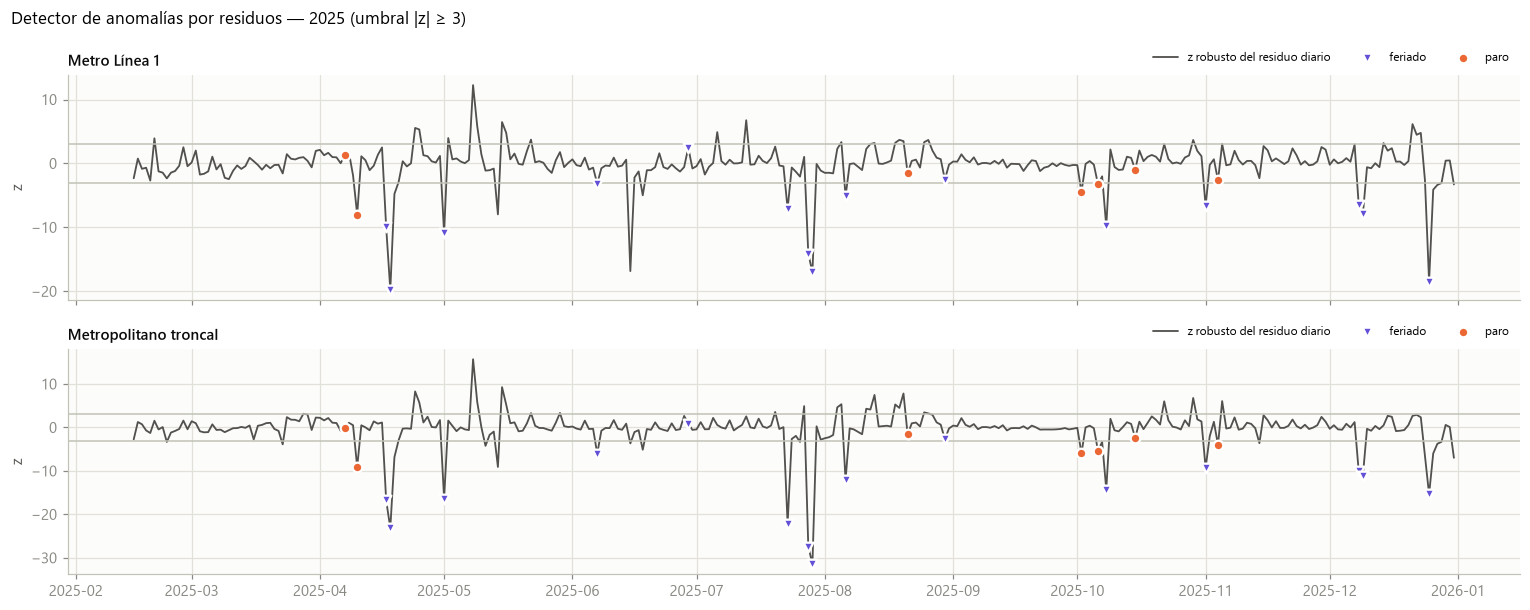

[figura] docs\images\model_v2\anomalias_z_2025.png


In [16]:
fig, axes = plt.subplots(2, 1, figsize=(14, 5.6), sharex=True)
for ax, s in zip(axes, ["metro_l1", "troncal"]):
    d = leer(s, "anomalias_residuo_diario.csv", parse_dates=["dia"])
    ax.plot(d.dia, d.z, color=INK2, lw=1.2, label="z robusto del residuo diario")
    ax.axhline(3, color=AXIS, lw=1); ax.axhline(-3, color=AXIS, lw=1)
    for tipo, mk, col in [("feriado", "v", "#6250d6"), ("paro", "o", "#eb6834")]:
        e = d[d.tipo_dia == tipo]
        ax.scatter(e.dia, e.z, marker=mk, s=40, color=col, edgecolor="white", linewidth=1.5, zorder=3, label=tipo)
    ax.set_title(TITULO[s], fontsize=10, loc="left"); ax.set_ylabel("z")
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower right", bbox_to_anchor=(1, 1.0))
fig.suptitle("Detector de anomalías por residuos — 2025 (umbral |z| ≥ 3)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
guardar(fig, "anomalias_z_2025.png")

In [17]:
top = pd.concat([leer(s, "anomalias_test_residuo_ganador.csv").head(5).assign(sistema=s) for s in SISTEMAS])
top[["sistema", "dia", "tipo_dia", "residuo_rel"]].round(3)

,sistema,dia,tipo_dia,residuo_rel
0,metro_l1,2025-12-25,feriado,-0.592
1,metro_l1,2025-11-01,feriado,-0.237
2,metro_l1,2025-12-24,vispera,-0.169
3,metro_l1,2025-12-21,normal,0.161
4,metro_l1,2025-12-14,normal,0.124
0,troncal,2025-12-25,feriado,-0.650
1,troncal,2025-12-24,vispera,-0.351
2,troncal,2025-12-09,feriado,-0.343
3,troncal,2025-11-01,feriado,-0.316
4,troncal,2025-12-08,feriado,-0.311


## 8. Conclusiones

1. **La evaluación de week08 sobreestimaba a AutoETS y a Chronos-Bolt.**
   - En 61 días con todos los días de la semana, AutoETS(24 h) es el peor modelo (WMAPE 0.25–0.58). Era
     el ganador de week08 en troncal, corredores y alimentadores. Sin estacionalidad semanal, colapsa en
     fines de semana (0.42–0.83). Con la historia completa mejora en martes (0.137 frente a 0.183 en L1),
     pero no en sábado (0.267 con ambas ventanas).
   - Chronos-Bolt, el ganador de week08 en L1, queda detrás de los modelos v2 en los 4 sistemas.
2. **Los modelos elegidos en validación superan a la mejor baseline** (`media_4sem`) en los 4 sistemas,
   con diferencias significativas (Diebold-Mariano p < 0.01). La reducción de WMAPE es de 19 % en Metro
   L1, 23 % en troncal, 28 % en corredores y 14 % en alimentadores.
3. **LightGBM directo es el mejor modelo individual.**
   - WMAPE de test: 0.100 en L1, 0.115 en troncal, 0.113 en corredores y 0.405 en alimentadores.
   - También es el más barato: 0.4–6 min por sistema para los 78 días, frente a 12–41 min de Chronos-2
     en CPU.
   - El ensemble elegido en validación no es significativamente distinto (p = 0.28–0.63).
4. **Chronos-2 zero-shot queda a 1–10 % de LightGBM sin entrenar nada.** Es consistente con la literatura
   de 2026 (los modelos fundacionales son un baseline fuerte en transporte).
   - Su covariable de feriado reduce el error en feriados frente a las baselines (L1: 0.46 frente a 0.67).
   - Aun así, LightGBM con banderas de calendario es mejor en feriados (0.25–0.48).
5. **Los días atípicos siguen siendo el punto débil.**
   - En L1, troncal y corredores el WMAPE es 0.35–0.60 en feriados, paros y vísperas, frente a 0.08–0.09
     en días normales.
   - Alimentadores es el sistema más difícil (0.39 incluso en días normales) por su cobertura irregular.
6. **Las bandas conformal cumplen lo prometido:** cubren entre 76.5 y 83.9 % con todos los modelos
   (objetivo: 80 %). En cambio, la banda fija de ±15 % de week08 cubre entre 16.7 y 79.6 %, y los
   cuantiles nativos de Chronos-2 se quedan en 69.5–75.7 %.
7. **Aforo:** la cascada del producto cumple RNF-01 en los 4 sistemas y AC-02 en 3.
   - F1-weighted: 0.91–0.93 en L1, troncal y corredores; 0.84 en alimentadores.
   - Alimentadores falla AC-02 en "Saturado" (F1 0.71).
   - La cascada supera al clasificador HistGB de week08 en L1 y alimentadores, y empata en corredores.
     En troncal, la moda histórica (0.920) iguala o supera a la cascada (0.907): el régimen
     hora × estación explica casi todo.
8. **AC-03 se cumple, pero no discrimina:** «siempre abordar» ya acierta entre 90 y 96 %. Con balanced
   accuracy, la regla aplicada al pronóstico obtiene 0.85, 0.90, 0.93 y 0.64, frente a 0.33–0.50 de la
   baseline. **Proponemos medir AC-03 con balanced accuracy.**
9. **Alertas:** el detector causal por residuos mejora claramente al IsolationForest de week08.
   - PR-AUC: 0.59, 0.69, 0.72 y 0.39, frente a 0.41, 0.46, 0.23 y 0.44 del IsolationForest. Gana en 3
     de 4 sistemas.
   - Detecta 12–14 de los 15 feriados evaluables, pero solo 2–4 de los 7 paros.
   - En general, los paros **reducen** la demanda formal: hasta −21 % en L1, −26 % en troncal y −30 % en
     corredores. En alimentadores, en cambio, la subieron: +15 % y +21 % los días 7 y 10 de abril.
   - Parte de los "falsos positivos" son eventos reales no etiquetados (por ejemplo, el 15-jun en L1,
     con −67 %).
10. **Decisión para el prototipo (week10).**
    - Modelo principal: el ganador de validación. Es el ensemble en L1, troncal y corredores, y LightGBM
      en alimentadores. Se ejecuta en batch diario (≈ 46 s por sistema con Chronos-2).
    - **Modo ligero:** LightGBM, que responde en milisegundos y no requiere torch. Sirve para despliegues
      con poca memoria y tiene precisión estadísticamente equivalente.